# 01 — Aprendizaje supervisado con UNSW-NB15
**Equipo 1 — clasificación de cinco ataques y análisis complementario Generic vs resto**

**Integrantes:** Integrante 1 · Integrante 2 · Integrante 3 · Integrante 4  
**Asignatura:** Análisis de Datos · **Periodo:** 2026-2

Notebook independiente y reproducible. Incluye imports, carga, EDA, particiones, selección de
variables, LR, SVM RBF, One-Class SVM, búsqueda de hiperparámetros, ajuste de umbral únicamente
en validación, prueba retenida, métricas, visualizaciones, análisis de errores y conclusiones.

**Alcance honesto:** el CSV no contiene clase `Normal`, ni `proto`, `service` o `state`.
`Generic` es un ataque y nunca se interpreta como benigno.

In [3]:
from pathlib import Path
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import softmax
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, average_precision_score,
    balanced_accuracy_score, calinski_harabasz_score, classification_report,
    completeness_score, confusion_matrix, davies_bouldin_score, f1_score,
    homogeneity_score, normalized_mutual_info_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score,
    v_measure_score
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, RobustScaler, label_binarize
from sklearn.svm import OneClassSVM, SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 110, "savefig.dpi": 180})

MODE = "supervisado"
ROOT = Path.cwd()
VIS_DIR = ROOT / "visualizaciones" / MODE
RES_DIR = ROOT / "resultados" / MODE
CACHE_DIR = ROOT / ".cache_ml"
for folder in (VIS_DIR, RES_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def locate_dataset(filename="UNSW-NB15_Dataset2.csv"):
    candidates = [ROOT / filename, ROOT / "data" / filename, ROOT.parent / filename]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"No se encontró {filename}. Ubíquelo en la carpeta del notebook, en data/ o en la carpeta padre."
    )


def savefig(name):
    path = VIS_DIR / name
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    return path


def stratified_sample_indices(y, n, random_state=RANDOM_STATE):
    """Devuelve índices posicionales de una muestra estratificada reproducible."""
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    idx, _ = train_test_split(
        np.arange(len(y)), train_size=n, stratify=y, random_state=random_state
    )
    return np.sort(idx)


def tune_f1_threshold(y_true, scores):
    """Ajusta el umbral solo con validación; scores altos significan 'resto de ataques'."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best = int(np.nanargmax(f1))
    return float(thresholds[best]), float(f1[best])


def multiclass_scores(model, X, class_order):
    """Obtiene una matriz comparable de puntuaciones/probabilidades por clase."""
    if hasattr(model, "predict_proba"):
        raw = model.predict_proba(X)
    else:
        raw = softmax(model.decision_function(X), axis=1)
    model_classes = model.classes_
    order = [int(np.where(model_classes == c)[0][0]) for c in class_order]
    return raw[:, order]


def purity_score(y_true, y_cluster):
    tab = pd.crosstab(pd.Series(y_cluster, name="cluster"), pd.Series(y_true, name="clase"))
    return float(tab.max(axis=1).sum() / tab.to_numpy().sum())

print("Entorno preparado.")

Entorno preparado.


## 1. Descripción del problema y preguntas

El objetivo principal es clasificar cada registro en uno de cinco ataques: `Backdoor`, `Probe`,
`Worm`, `Generic` o `DoS`. Como análisis complementario se estudia la separabilidad de `Generic`
frente a los otros cuatro ataques; este experimento permite comparar clasificadores discriminativos
con One-Class SVM, pero **no** mide tráfico normal frente a malicioso.

Preguntas: (1) ¿qué variables de conexión/comportamiento aportan más información? (2) ¿LR o SVM
logra mejor F1 macro sobre la misma prueba? (3) ¿qué clases presentan más errores? (4) ¿qué aporta
One-Class SVM cuando aprende únicamente el patrón de `Generic`?

In [4]:
t0 = time.time()
DATA_PATH = locate_dataset()
df_raw = pd.read_csv(DATA_PATH)
TARGET = "attack"
FEATURES = [c for c in df_raw.columns if c != TARGET]
EXPECTED_CLASSES = ["Backdoor", "Probe", "Worm", "Generic", "DoS"]

assert TARGET in df_raw.columns
assert len(FEATURES) == 39
assert set(df_raw[TARGET].unique()) == set(EXPECTED_CLASSES)
assert all(pd.api.types.is_numeric_dtype(df_raw[c]) for c in FEATURES)

class_counts_raw = df_raw[TARGET].value_counts()
missing_total = int(df_raw.isna().sum().sum())
inf_total = int(np.isinf(df_raw[FEATURES].to_numpy()).sum())
exact_duplicates = int(df_raw.duplicated().sum())
feature_duplicates = int(df_raw.duplicated(subset=FEATURES).sum())
conflicting_feature_groups = int(
    (df_raw.groupby(FEATURES, sort=False, dropna=False)[TARGET].nunique() > 1).sum()
)

print(f"Archivo: {DATA_PATH}")
print(f"Dimensión original: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print(f"Variables predictoras numéricas: {len(FEATURES)}")
print(f"Faltantes: {missing_total:,} | Infinitos: {inf_total:,}")
print(f"Duplicados exactos: {exact_duplicates:,} ({exact_duplicates/len(df_raw):.1%})")
print(f"Duplicados por predictores: {feature_duplicates:,} | grupos con etiquetas conflictivas: {conflicting_feature_groups}")
display(pd.DataFrame({"n": class_counts_raw, "%": (100 * class_counts_raw / len(df_raw)).round(2)}))

# Los duplicados exactos producirían el mismo vector en train y test y sobreestimarían la generalización.
# Se conservan en el EDA para describir el archivo recibido, pero se eliminan antes de modelar.
df = df_raw.drop_duplicates().reset_index(drop=True)
class_counts_unique = df[TARGET].value_counts()
print(f"Registros únicos usados en modelado: {len(df):,}")
display(pd.DataFrame({"n_unicos": class_counts_unique, "%_unicos": (100 * class_counts_unique / len(df)).round(2)}))

Archivo: g:\Mi unidad\ITM\2026-2\Analisis de datos\Entregable 4\entregable-machine-learning-2026-2\UNSW-NB15_Dataset2.csv
Dimensión original: 340,693 filas × 40 columnas
Variables predictoras numéricas: 39
Faltantes: 0 | Infinitos: 0
Duplicados exactos: 198,253 (58.2%)
Duplicados por predictores: 198,253 | grupos con etiquetas conflictivas: 0


,n,%
attack,,
Backdoor,95494,28.03
Probe,72789,21.36
Worm,60855,17.86
Generic,57309,16.82
DoS,54246,15.92


Registros únicos usados en modelado: 142,440


,n_unicos,%_unicos
attack,,
Backdoor,87523,61.45
Worm,27892,19.58
Probe,19203,13.48
Generic,6110,4.29
DoS,1712,1.20


## 2. EDA y análisis de variables disponibles

El archivo recibido **no contiene** `proto`, `service` ni `state`; tampoco contiene clase `Normal`.
No se inventan ni se codifican esas columnas. En su lugar se analizan las variables disponibles:

- **Volumen/tasa:** paquetes, bytes, cargas, pérdidas y medias.
- **Temporización:** duración, intervalos, jitter y tiempos TCP.
- **Estado/conexión:** TTL, ventanas TCP y `ct_state_ttl`.
- **Contexto histórico:** contadores `ct_*` de origen, destino, servicio y puertos.
- **Indicadores de aplicación:** FTP, HTTP, profundidad y longitud de respuesta.

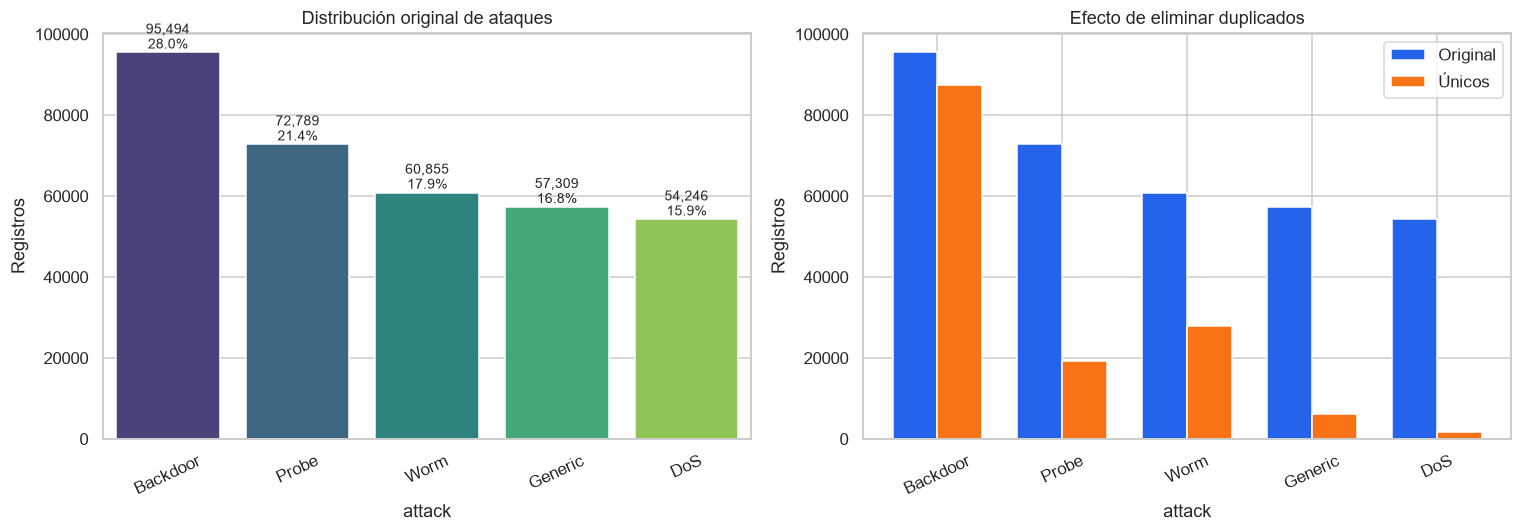

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/supervisado/01_eda_distribucion_clases.png')

In [5]:
order = class_counts_raw.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette("viridis", len(order))
sns.barplot(x=class_counts_raw.index, y=class_counts_raw.values, hue=class_counts_raw.index, ax=axes[0], palette=colors, legend=False)
axes[0].set(title="Distribución original de ataques", xlabel="attack", ylabel="Registros")
axes[0].tick_params(axis="x", rotation=25)
for i, value in enumerate(class_counts_raw.values):
    axes[0].text(i, value, f"{value:,}\n{value/len(df_raw):.1%}", ha="center", va="bottom", fontsize=9)

unique_aligned = class_counts_unique.reindex(order)
x = np.arange(len(order))
axes[1].bar(x - 0.18, class_counts_raw.reindex(order).values, width=0.36, label="Original", color="#2563EB")
axes[1].bar(x + 0.18, unique_aligned.values, width=0.36, label="Únicos", color="#F97316")
axes[1].set_xticks(x, order, rotation=25)
axes[1].set(title="Efecto de eliminar duplicados", xlabel="attack", ylabel="Registros")
axes[1].legend()
savefig("01_eda_distribucion_clases.png")

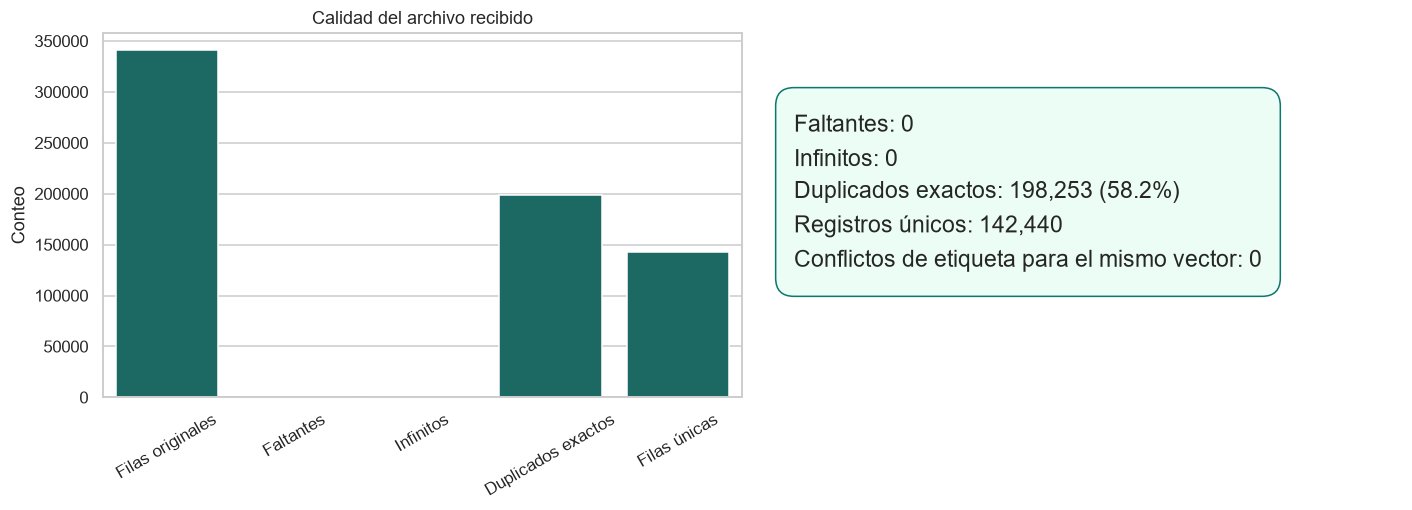

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/supervisado/02_eda_calidad_duplicados.png')

In [6]:
quality = pd.DataFrame({
    "indicador": ["Filas originales", "Faltantes", "Infinitos", "Duplicados exactos", "Filas únicas"],
    "valor": [len(df_raw), missing_total, inf_total, exact_duplicates, len(df)]
})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=quality, x="indicador", y="valor", ax=axes[0], color="#0F766E")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set(title="Calidad del archivo recibido", xlabel="", ylabel="Conteo")
axes[1].axis("off")
quality_text = (
    f"Faltantes: {missing_total:,}\n"
    f"Infinitos: {inf_total:,}\n"
    f"Duplicados exactos: {exact_duplicates:,} ({exact_duplicates/len(df_raw):.1%})\n"
    f"Registros únicos: {len(df):,}\n"
    f"Conflictos de etiqueta para el mismo vector: {conflicting_feature_groups}"
)
axes[1].text(0.05, 0.8, quality_text, fontsize=15, va="top", linespacing=1.6,
             bbox=dict(boxstyle="round,pad=0.8", facecolor="#ECFDF5", edgecolor="#0F766E"))
savefig("02_eda_calidad_duplicados.png")

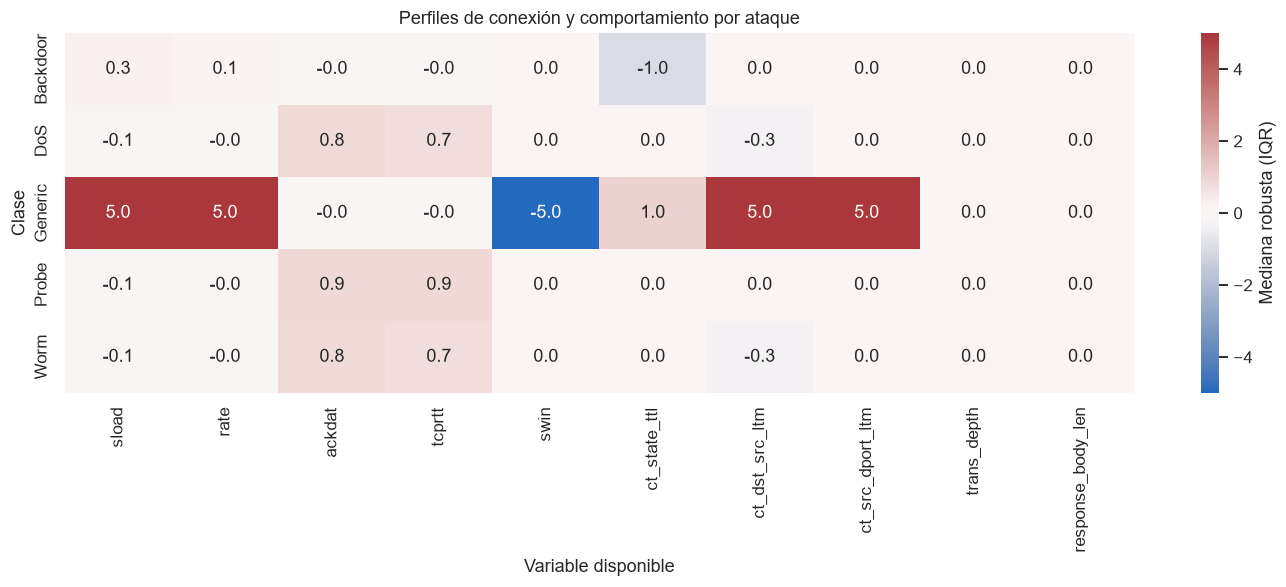

Variables destacadas por grupo: ['sload', 'rate', 'ackdat', 'tcprtt', 'swin', 'ct_state_ttl', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'trans_depth', 'response_body_len']


In [7]:
feature_groups = {
    "volumen_tasa": ["spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload", "sloss", "dloss", "smean", "dmean"],
    "tiempo": ["dur", "sinpkt", "dinpkt", "sjit", "djit", "tcprtt", "synack", "ackdat"],
    "estado_conexion": ["sttl", "dttl", "swin", "dwin", "ct_state_ttl"],
    "contexto": [c for c in FEATURES if c.startswith("ct_") and c != "ct_state_ttl"],
    "aplicacion": ["trans_depth", "response_body_len", "is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd", "is_sm_ips_ports"]
}
# Perfil robusto: medianas por clase, estandarizadas por mediana/IQR global.
medians = df.groupby(TARGET)[FEATURES].median()
global_med = df[FEATURES].median()
iqr = (df[FEATURES].quantile(.75) - df[FEATURES].quantile(.25)).replace(0, 1)
robust_profile = ((medians - global_med) / iqr).clip(-5, 5)
profile_features = []
for group, cols in feature_groups.items():
    # dos variables con mayor variación entre clases por grupo
    profile_features += robust_profile[cols].var().nlargest(min(2, len(cols))).index.tolist()
profile_features = list(dict.fromkeys(profile_features))

plt.figure(figsize=(13, 5.5))
sns.heatmap(robust_profile[profile_features], cmap="vlag", center=0, annot=True, fmt=".1f", cbar_kws={"label": "Mediana robusta (IQR)"})
plt.title("Perfiles de conexión y comportamiento por ataque")
plt.xlabel("Variable disponible")
plt.ylabel("Clase")
savefig("03_eda_perfiles_comportamiento.png")
print("Variables destacadas por grupo:", profile_features)

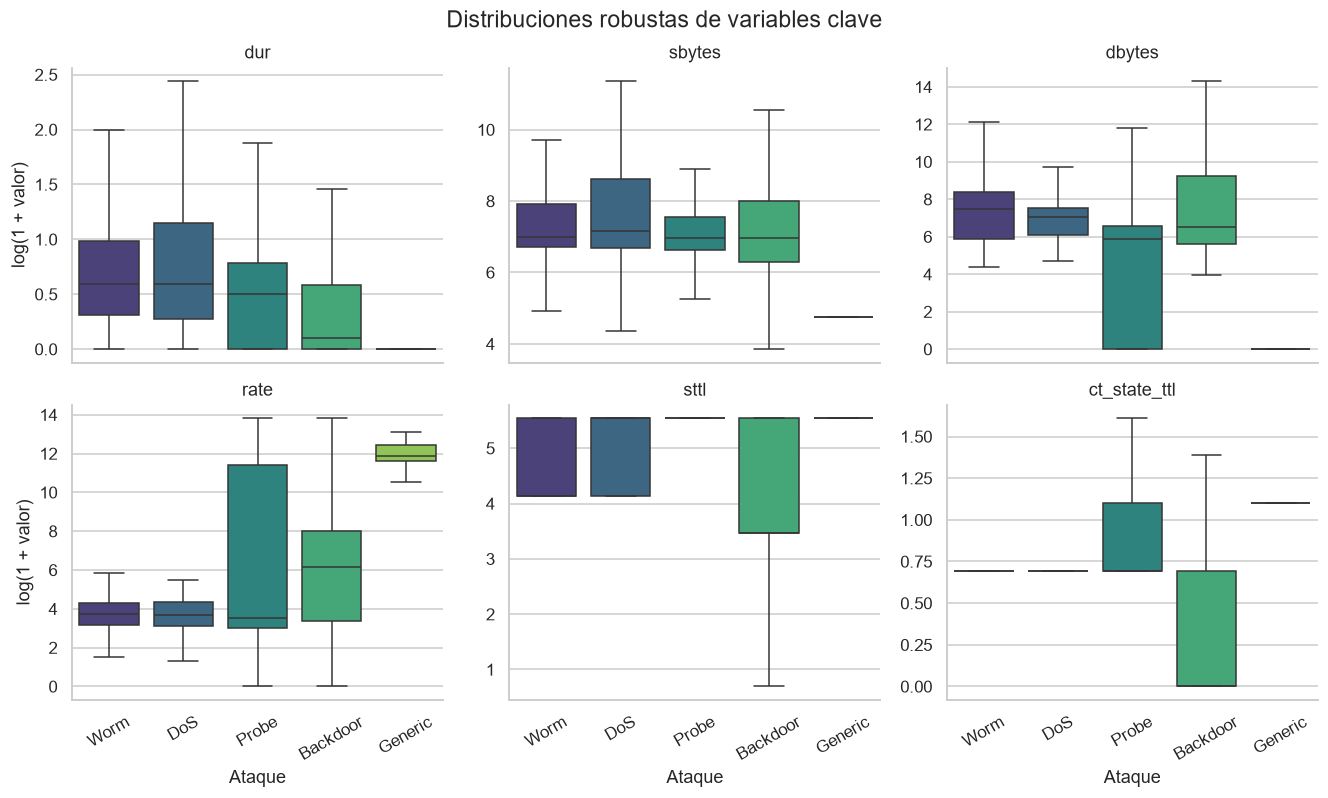

In [8]:
plot_features = ["dur", "sbytes", "dbytes", "rate", "sttl", "ct_state_ttl"]
sample_idx = stratified_sample_indices(df[TARGET], min(30000, len(df)))
eda_sample = df.iloc[sample_idx].copy()
long = eda_sample.melt(id_vars=TARGET, value_vars=plot_features, var_name="variable", value_name="valor")
long["log1p_valor"] = np.log1p(long["valor"].clip(lower=0))
g = sns.catplot(
    data=long, x=TARGET, y="log1p_valor", col="variable", col_wrap=3,
    kind="box", showfliers=False, sharey=False, height=3.4, aspect=1.2,
    hue=TARGET, palette="viridis", legend=False
)
g.set_axis_labels("Ataque", "log(1 + valor)")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)
g.fig.suptitle("Distribuciones robustas de variables clave", y=1.02, fontsize=15)
plt.savefig(VIS_DIR / "04_eda_boxplots_log.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

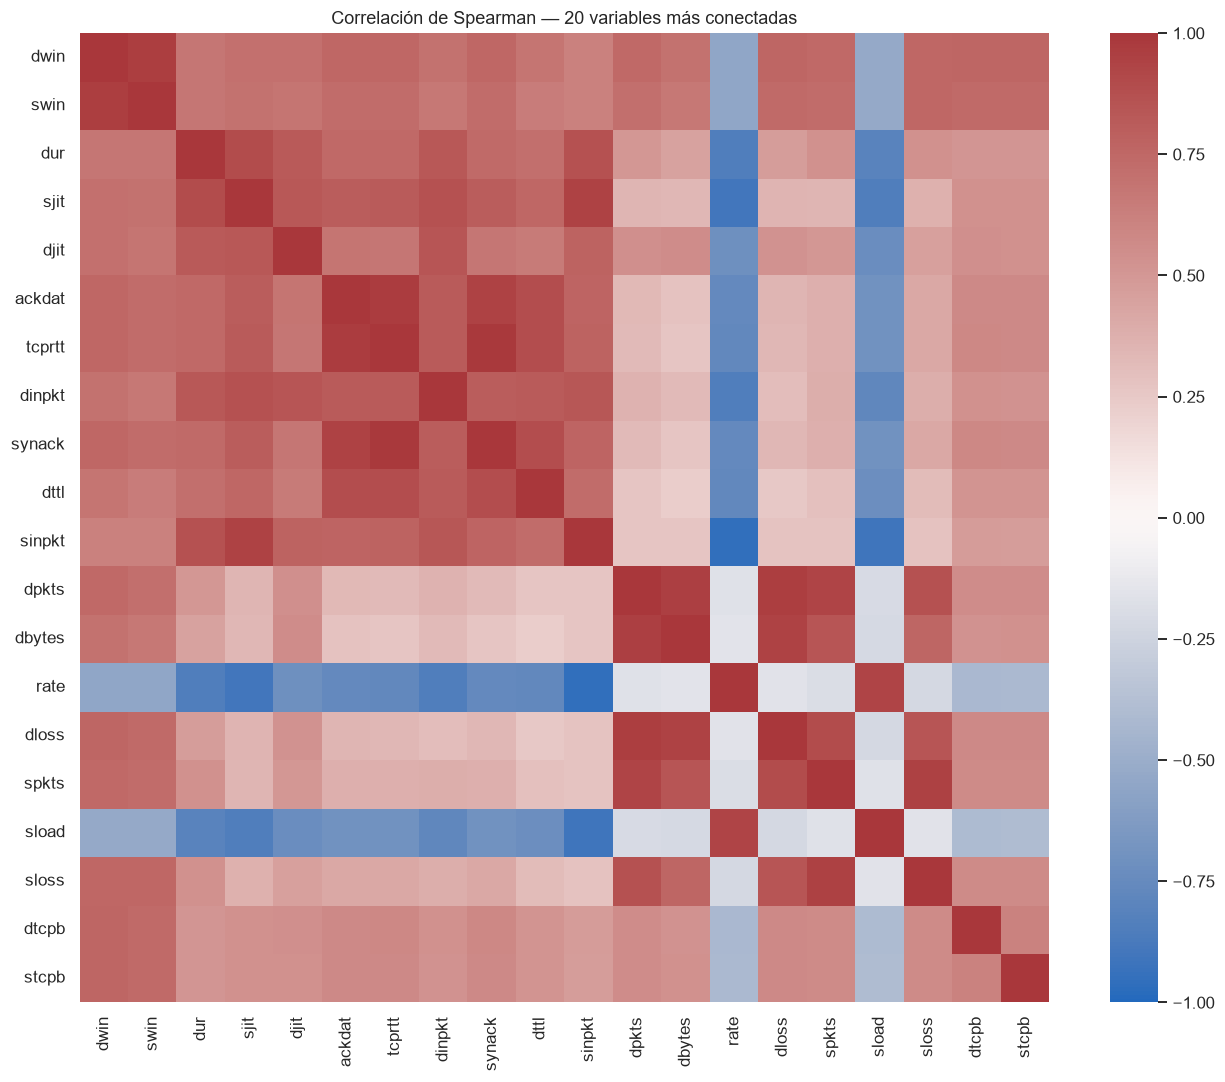

,% outliers IQR
swin,24.13
dmean,20.33
dbytes,20.20
sload,16.96
spkts,15.81
trans_depth,15.41
ct_flw_http_mthd,15.41
rate,14.35
smean,14.22
djit,13.74


In [9]:
corr = df[FEATURES].corr(method="spearman")
# Mostrar las 20 variables con mayor correlación media absoluta para conservar legibilidad.
selected_corr = corr.abs().mean().nlargest(20).index
plt.figure(figsize=(12, 10))
sns.heatmap(corr.loc[selected_corr, selected_corr], cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman — 20 variables más conectadas")
savefig("05_eda_correlacion_spearman.png")

# Porcentaje de outliers por regla IQR en registros únicos.
q1, q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
iqr_raw = q3 - q1
outlier_rate = (((df[FEATURES] < (q1 - 1.5 * iqr_raw)) | (df[FEATURES] > (q3 + 1.5 * iqr_raw))).mean() * 100).sort_values(ascending=False)
display(outlier_rate.head(10).rename("% outliers IQR").to_frame().round(2))

## 3. Partición y preprocesamiento sin fuga

Primero se eliminan duplicados exactos; luego se reserva 15% para prueba y 15% para validación,
siempre estratificando por `attack`. La prueba no participa en selección de variables, búsqueda de
hiperparámetros ni ajuste de umbral. Mutual Information se calcula exclusivamente con entrenamiento;
después se elige el menor conjunto que acumula 90% de la MI (entre 15 y 30 variables). El escalador
se ajusta con entrenamiento y se reutiliza sin reajuste en validación y prueba.

In [10]:
X = df[FEATURES].copy()
y_text = df[TARGET].copy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_.tolist()

X_train, X_temp, y_train, y_temp, attack_train, attack_temp = train_test_split(
    X, y, y_text, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test, attack_val, attack_test = train_test_split(
    X_temp, y_temp, attack_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

for obj in (X_train, X_val, X_test, attack_train, attack_val, attack_test):
    obj.reset_index(drop=True, inplace=True)
y_train, y_val, y_test = map(np.asarray, (y_train, y_val, y_test))

split_summary = pd.DataFrame({
    "conjunto": ["train", "validación", "prueba"],
    "n": [len(X_train), len(X_val), len(X_test)],
    "porcentaje": [len(X_train)/len(df), len(X_val)/len(df), len(X_test)/len(df)]
})
display(split_summary.style.format({"porcentaje": "{:.1%}"}))

,conjunto,n,porcentaje
0,train,99708,70.0%
1,validación,21366,15.0%
2,prueba,21366,15.0%


## 4. Selección de variables con Mutual Information

La MI se calcula solo en entrenamiento. El número de variables no depende del número de clases: se
escoge el menor conjunto que concentra 90% de la información mutua observada, acotado entre 15 y 30
para conservar señal suficiente y reducir el costo del SVM.

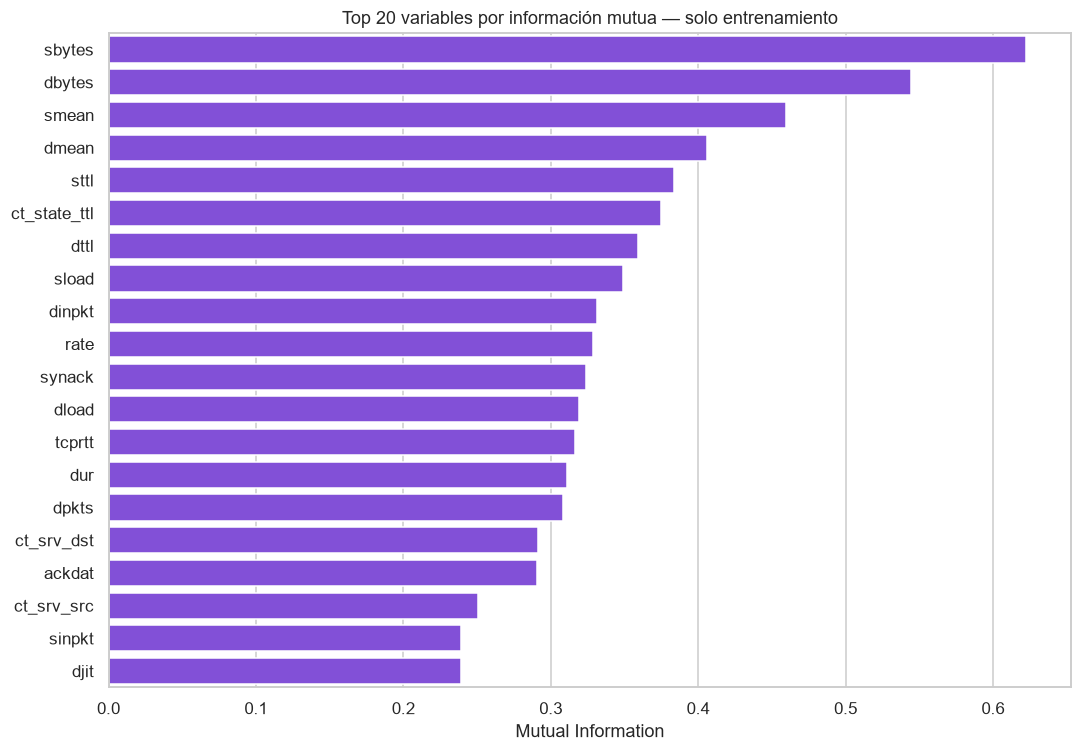

,variable,MI
0,sbytes,0.622094
1,dbytes,0.544249
2,smean,0.459801
3,dmean,0.406285
4,sttl,0.383360
5,ct_state_ttl,0.374785
6,dttl,0.359170
7,sload,0.348732
8,dinpkt,0.331684
9,rate,0.328745


Se usarán 27 variables (criterio: 90% de MI, límites 15–30).
['sbytes', 'dbytes', 'smean', 'dmean', 'sttl', 'ct_state_ttl', 'dttl', 'sload', 'dinpkt', 'rate', 'synack', 'dload', 'tcprtt', 'dur', 'dpkts', 'ct_srv_dst', 'ackdat', 'ct_srv_src', 'sinpkt', 'djit', 'sjit', 'dloss', 'spkts', 'sloss', 'ct_dst_src_ltm', 'ct_dst_ltm', 'ct_dst_sport_ltm']


In [11]:
mi_sample_idx = stratified_sample_indices(y_train, min(50000, len(y_train)))
mi_values = mutual_info_classif(
    X_train.iloc[mi_sample_idx], y_train[mi_sample_idx], random_state=RANDOM_STATE
)
mi_df = pd.DataFrame({"variable": FEATURES, "MI": mi_values}).sort_values("MI", ascending=False)
mi_positive = mi_df["MI"].clip(lower=0)
mi_cumulative = mi_positive.cumsum() / max(mi_positive.sum(), 1e-12)
k_mi = int(np.searchsorted(mi_cumulative.to_numpy(), 0.90) + 1)
k_mi = int(np.clip(k_mi, 15, 30))
selected_features = mi_df.head(k_mi)["variable"].tolist()
plt.figure(figsize=(10, 7))
sns.barplot(data=mi_df.head(20), x="MI", y="variable", color="#7C3AED")
plt.title("Top 20 variables por información mutua — solo entrenamiento")
plt.xlabel("Mutual Information")
plt.ylabel("")
savefig("06_seleccion_variables_mi.png")
display(mi_df.head(20).reset_index(drop=True))
print(f"Se usarán {k_mi} variables (criterio: 90% de MI, límites 15–30).")
print(selected_features)

## 5. Componente supervisado principal: cinco ataques

**Logistic Regression** es un baseline lineal interpretable, rápido y probabilístico; puede fallar
ante fronteras no lineales. **SVM RBF** modela fronteras complejas y funciona bien con variables
escaladas, pero su costo crece más que linealmente. Por ello, LR usa todo el entrenamiento y SVM
una muestra estratificada de 12.000 registros; ambos se evalúan sobre la misma prueba completa.
`class_weight='balanced'` compensa el fuerte desbalance que queda al retirar duplicados. `C` y
`gamma` se eligen por F1 macro con GridSearchCV de 3 folds dentro del entrenamiento; nunca se
optimiza sobre validación ni prueba.

In [12]:
X_train_sup = X_train[selected_features]
X_val_sup = X_val[selected_features]
X_test_sup = X_test[selected_features]

# GridSearchCV se ajusta únicamente con muestras del entrenamiento; validación y prueba no entran.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
lr_train_idx = stratified_sample_indices(y_train, min(30000, len(y_train)), RANDOM_STATE + 1)
X_train_lr, y_train_lr = X_train_sup.iloc[lr_train_idx], y_train[lr_train_idx]
lr_pipe = Pipeline([
    ("scale", RobustScaler()),
    ("clf", LogisticRegression(max_iter=1400, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE))
])
lr_grid = GridSearchCV(
    lr_pipe, {"clf__C": [0.1, 1.0, 10.0]}, scoring="f1_macro",
    cv=cv, n_jobs=-1, refit=True
)
start = time.time()
lr_grid.fit(X_train_lr, y_train_lr)
best_lr = lr_grid.best_estimator_
lr_val_f1 = f1_score(y_val, best_lr.predict(X_val_sup), average="macro")
print(f"LR GridSearch listo en {(time.time()-start)/60:.1f} min | n_train={len(X_train_lr):,} | {lr_grid.best_params_} | CV F1-macro={lr_grid.best_score_:.4f} | validación={lr_val_f1:.4f}")

# SVM: muestreo estratificado permitido por el tamaño del dataset y el costo O(n²–n³).
svm_train_idx = stratified_sample_indices(y_train, min(12000, len(y_train)), RANDOM_STATE)
X_train_svm, y_train_svm = X_train_sup.iloc[svm_train_idx], y_train[svm_train_idx]
svm_pipe = Pipeline([
    ("scale", RobustScaler()),
    ("clf", SVC(kernel="rbf", class_weight="balanced", cache_size=1800, random_state=RANDOM_STATE))
])
svm_grid = GridSearchCV(
    svm_pipe,
    {"clf__C": [1.0, 5.0], "clf__gamma": ["scale", 0.05]},
    scoring="f1_macro", cv=cv, n_jobs=-1, refit=True
)
start = time.time()
svm_grid.fit(X_train_svm, y_train_svm)
best_svm = svm_grid.best_estimator_
svm_val_f1 = f1_score(y_val, best_svm.predict(X_val_sup), average="macro")
print(f"SVM GridSearch listo en {(time.time()-start)/60:.1f} min | n_train={len(X_train_svm):,} | {svm_grid.best_params_} | CV F1-macro={svm_grid.best_score_:.4f} | validación={svm_val_f1:.4f}")

LR GridSearch listo en 1.7 min | n_train=30,000 | {'clf__C': 1.0} | CV F1-macro=0.6070 | validación=0.6014
SVM GridSearch listo en 1.3 min | n_train=12,000 | {'clf__C': 5.0, 'clf__gamma': 0.05} | CV F1-macro=0.7393 | validación=0.7668


In [13]:
def evaluate_multiclass(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    scores = multiclass_scores(model, X_eval, np.arange(len(class_names)))
    y_bin = label_binarize(y_eval, classes=np.arange(len(class_names)))
    return {
        "Modelo": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_eval, pred),
        "Precision macro": precision_score(y_eval, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_eval, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_eval, pred, average="macro", zero_division=0),
        "ROC-AUC OVR macro": roc_auc_score(y_bin, scores, average="macro", multi_class="ovr"),
        "PR-AUC macro": average_precision_score(y_bin, scores, average="macro"),
        "pred": pred,
        "scores": scores,
    }

lr_result = evaluate_multiclass("Logistic Regression", best_lr, X_test_sup, y_test)
svm_result = evaluate_multiclass("SVM RBF", best_svm, X_test_sup, y_test)
model_results = [lr_result, svm_result]
metrics_multiclass = pd.DataFrame([
    {k: v for k, v in r.items() if k not in {"pred", "scores"}} for r in model_results
]).set_index("Modelo")
metrics_multiclass.to_csv(RES_DIR / "metricas_supervisado_multiclase.csv")
display(metrics_multiclass.style.format("{:.4f}"))

for r in model_results:
    print(f"\n{r['Modelo']} — reporte por clase")
    print(classification_report(y_test, r["pred"], target_names=class_names, digits=4, zero_division=0))

,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC OVR macro,PR-AUC macro
Modelo,,,,,,,
Logistic Regression,0.6971,0.7493,0.6000,0.7493,0.5999,0.9402,0.6990
SVM RBF,0.8714,0.8326,0.7480,0.8326,0.7677,0.9356,0.7639



Logistic Regression — reporte por clase
              precision    recall  f1-score   support

    Backdoor     0.9852    0.6877    0.8100     13128
         DoS     0.0805    0.6732    0.1438       257
     Generic     0.7252    0.9651    0.8281       916
       Probe     0.4253    0.8709    0.5715      2881
        Worm     0.7839    0.5497    0.6462      4184

    accuracy                         0.6971     21366
   macro avg     0.6000    0.7493    0.5999     21366
weighted avg     0.8482    0.6971    0.7385     21366


SVM RBF — reporte por clase
              precision    recall  f1-score   support

    Backdoor     0.9747    0.8802    0.9250     13128
         DoS     0.2458    0.6265    0.3531       257
     Generic     0.9942    0.9367    0.9646       916
       Probe     0.6112    0.8841    0.7228      2881
        Worm     0.9140    0.8358    0.8732      4184

    accuracy                         0.8714     21366
   macro avg     0.7480    0.8326    0.7677     21366
weighte

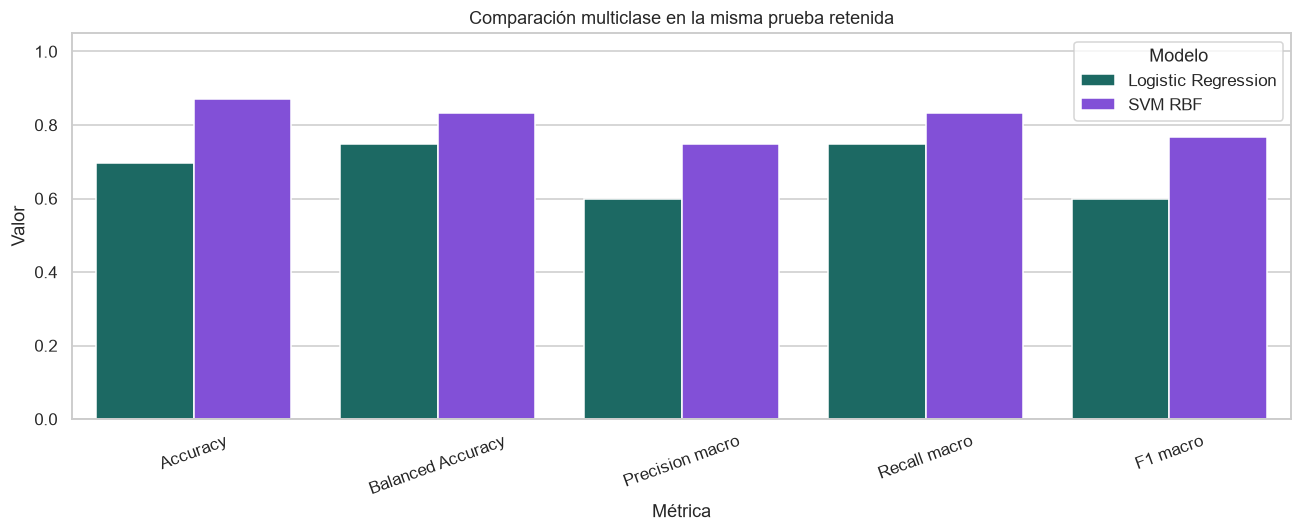

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/supervisado/07_supervisado_comparacion_metricas.png')

In [14]:
plot_df = metrics_multiclass[["Accuracy", "Balanced Accuracy", "Precision macro", "Recall macro", "F1 macro"]].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Métrica", y="Valor", hue="Modelo", palette=["#0F766E", "#7C3AED"])
plt.ylim(0, 1.05)
plt.title("Comparación multiclase en la misma prueba retenida")
plt.xticks(rotation=20)
savefig("07_supervisado_comparacion_metricas.png")

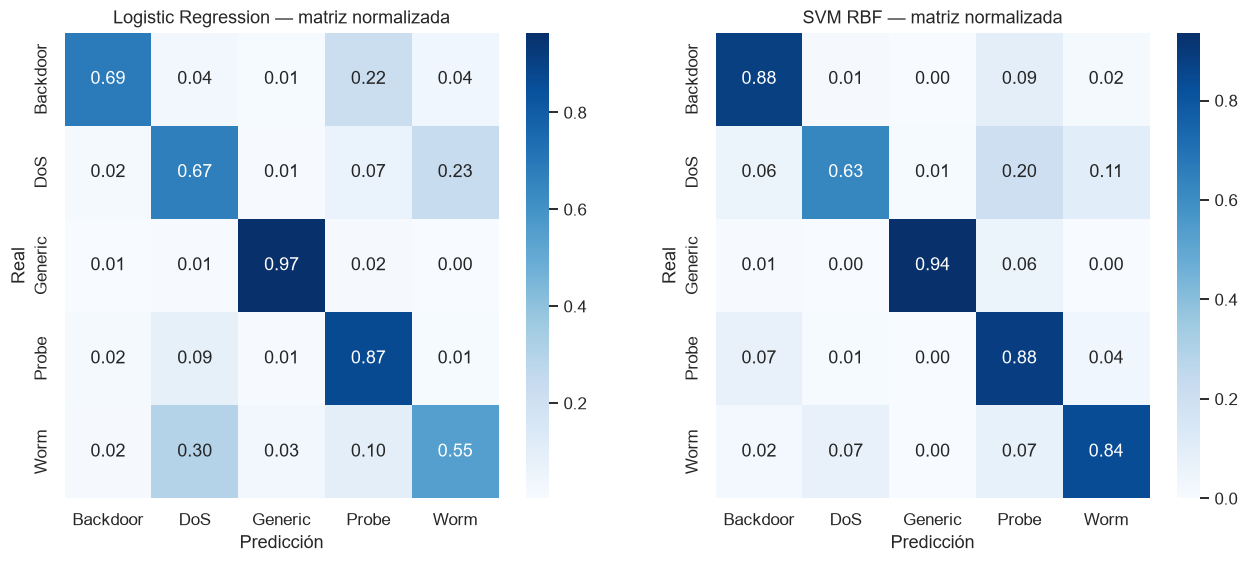

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, r in zip(axes, model_results):
    cm = confusion_matrix(y_test, r["pred"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set(title=f"{r['Modelo']} — matriz normalizada", xlabel="Predicción", ylabel="Real")
plt.savefig(VIS_DIR / "08_supervisado_matrices_confusion.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

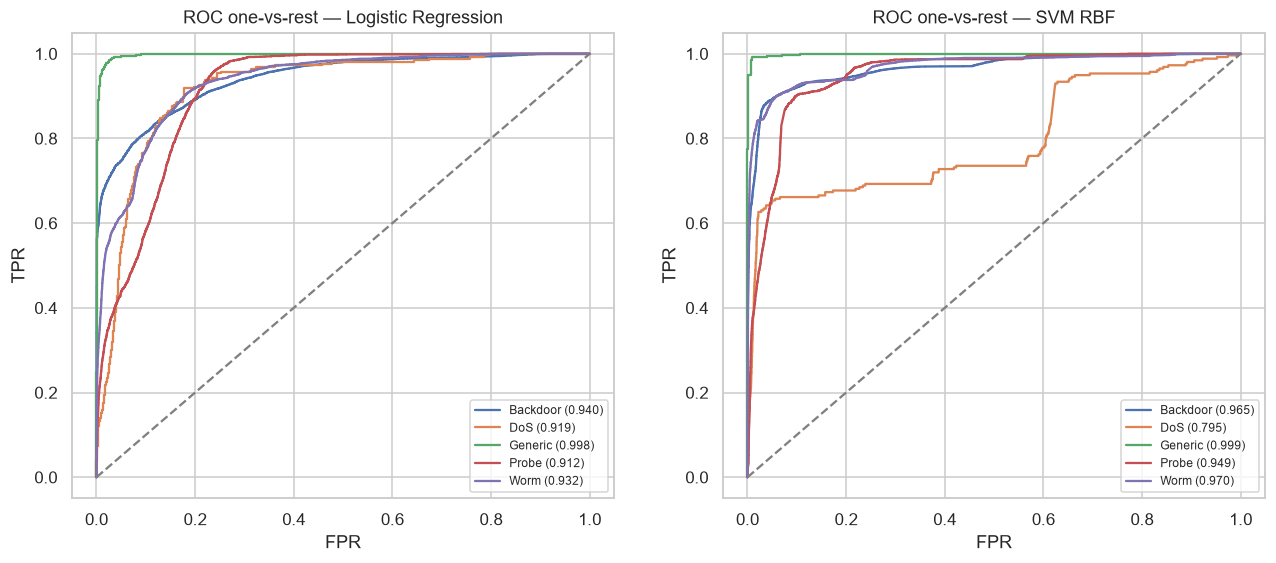

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
y_test_bin = label_binarize(y_test, classes=np.arange(len(class_names)))
for ax, r in zip(axes, model_results):
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], r["scores"][:, i])
        auc = roc_auc_score(y_test_bin[:, i], r["scores"][:, i])
        ax.plot(fpr, tpr, label=f"{cls} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(title=f"ROC one-vs-rest — {r['Modelo']}", xlabel="FPR", ylabel="TPR")
    ax.legend(fontsize=8)
plt.savefig(VIS_DIR / "09_supervisado_curvas_roc_multiclase.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

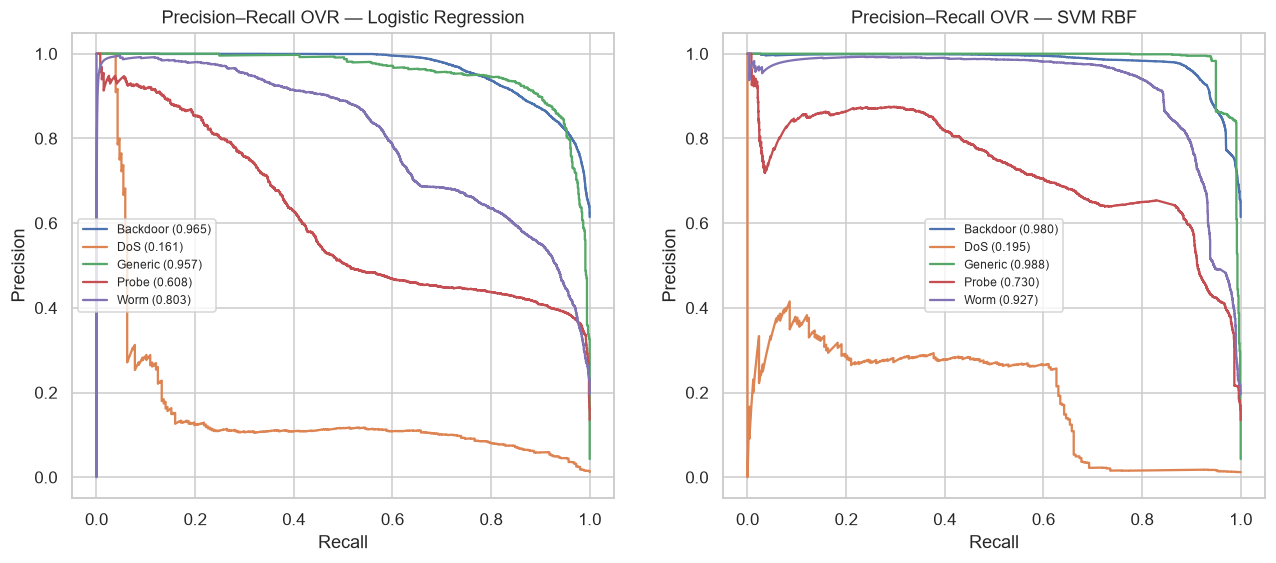

In [17]:
# Curvas Precision–Recall multiclase one-vs-rest (las áreas exactas también están en la tabla).
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, r in zip(axes, model_results):
    for i, cls in enumerate(class_names):
        p_curve, r_curve, _ = precision_recall_curve(y_test_bin[:, i], r["scores"][:, i])
        ap = average_precision_score(y_test_bin[:, i], r["scores"][:, i])
        ax.plot(r_curve, p_curve, label=f"{cls} ({ap:.3f})")
    ax.set(title=f"Precision–Recall OVR — {r['Modelo']}", xlabel="Recall", ylabel="Precision")
    ax.legend(fontsize=8)
plt.savefig(VIS_DIR / "10_supervisado_curvas_pr_multiclase.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

## 6. Complemento: `Generic` frente al resto y ajuste de umbral

Para LR y SVM, la puntuación binaria es `1 - score(Generic)`. One-Class SVM se entrena solo con
ejemplos `Generic`; un score alto indica novedad. El umbral de LR y SVM se elige con validación,
no con la prueba. Para One-Class SVM, `nu` y `gamma` se buscan con GridSearchCV sobre los ejemplos
`Generic` y el umbral es el que trae el modelo por defecto.


In [18]:
generic_label = int(label_encoder.transform(["Generic"])[0])
y_val_anom = (y_val != generic_label).astype(int)
y_test_anom = (y_test != generic_label).astype(int)

def anomaly_scores_from_multiclass(model, X_eval):
    scores = multiclass_scores(model, X_eval, np.arange(len(class_names)))
    return 1.0 - scores[:, generic_label]

binary_rows = []
binary_details = {}
for name, model in [("Logistic Regression", best_lr), ("SVM RBF", best_svm)]:
    val_scores = anomaly_scores_from_multiclass(model, X_val_sup)
    threshold, val_f1 = tune_f1_threshold(y_val_anom, val_scores)
    test_scores = anomaly_scores_from_multiclass(model, X_test_sup)
    pred = (test_scores >= threshold).astype(int)
    row = {
        "Modelo": name, "Umbral": threshold, "F1 validación": val_f1,
        "Precision": precision_score(y_test_anom, pred),
        "Recall": recall_score(y_test_anom, pred),
        "F1": f1_score(y_test_anom, pred),
        "ROC-AUC": roc_auc_score(y_test_anom, test_scores),
        "PR-AUC": average_precision_score(y_test_anom, test_scores),
    }
    binary_rows.append(row)
    binary_details[name] = {"scores": test_scores, "pred": pred, "threshold": threshold}

# One-Class SVM: escalador ajustado solo con Generic de entrenamiento.
generic_train_mask = y_train == generic_label
X_generic_train = X_train.loc[generic_train_mask].reset_index(drop=True)
oc_scaler = RobustScaler().fit(X_generic_train)
X_generic_scaled = oc_scaler.transform(X_generic_train)
X_val_oc = oc_scaler.transform(X_val)
X_test_oc = oc_scaler.transform(X_test)

# GridSearchCV exige un vector y; como solo hay ejemplos Generic se usa una etiqueta constante
# y como puntuación la fracción de registros Generic que el modelo acepta como normales.
def inlier_rate(estimator, X, y=None):
    return float(np.mean(estimator.predict(X) == 1))

oc_grid = GridSearchCV(
    OneClassSVM(kernel="rbf", cache_size=1800),
    {"nu": [0.01, 0.03, 0.05, 0.10], "gamma": ["scale", 0.01]},
    scoring=inlier_rate, cv=3, n_jobs=-1, refit=True
)
oc_grid.fit(X_generic_scaled, np.ones(len(X_generic_scaled)))
oc_model = oc_grid.best_estimator_
oc_search_rows = [
    {"nu": p["nu"], "gamma": p["gamma"], "inlier_rate_cv": s}
    for p, s in zip(oc_grid.cv_results_["params"], oc_grid.cv_results_["mean_test_score"])
]

# Umbral por defecto del modelo: decision_function < 0 se considera novedad.
oc_val_scores = -oc_model.decision_function(X_val_oc).ravel()
oc_val_f1 = f1_score(y_val_anom, (oc_val_scores >= 0).astype(int))
best_oc = {
    "nu": oc_grid.best_params_["nu"], "gamma": oc_grid.best_params_["gamma"],
    "threshold": 0.0, "val_f1": oc_val_f1, "model": oc_model
}

oc_test_scores = -best_oc["model"].decision_function(X_test_oc).ravel()
oc_pred = (oc_test_scores >= best_oc["threshold"]).astype(int)
oc_row = {
    "Modelo": "One-Class SVM", "Umbral": best_oc["threshold"], "F1 validación": best_oc["val_f1"],
    "Precision": precision_score(y_test_anom, oc_pred),
    "Recall": recall_score(y_test_anom, oc_pred),
    "F1": f1_score(y_test_anom, oc_pred),
    "ROC-AUC": roc_auc_score(y_test_anom, oc_test_scores),
    "PR-AUC": average_precision_score(y_test_anom, oc_test_scores),
}
binary_rows.append(oc_row)
binary_details["One-Class SVM"] = {"scores": oc_test_scores, "pred": oc_pred, "threshold": best_oc["threshold"]}

metrics_binary = pd.DataFrame(binary_rows).set_index("Modelo")
metrics_binary.to_csv(RES_DIR / "metricas_generic_vs_resto.csv")
pd.DataFrame(oc_search_rows).to_csv(RES_DIR / "busqueda_oneclass_svm.csv", index=False)
print("Mejor One-Class SVM:", {k: v for k, v in best_oc.items() if k != "model"})
display(metrics_binary.style.format("{:.4f}"))

Mejor One-Class SVM: {'nu': 0.01, 'gamma': 0.01, 'threshold': 0.0, 'val_f1': 0.9997799887549809}


,Umbral,F1 validación,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,,
Logistic Regression,0.1250,0.9956,0.9938,0.9970,0.9954,0.9976,0.9999
SVM RBF,0.7663,0.9982,0.9973,0.9996,0.9985,0.9989,0.9999
One-Class SVM,0.0000,0.9998,0.9996,0.9998,0.9997,0.9999,1.0000


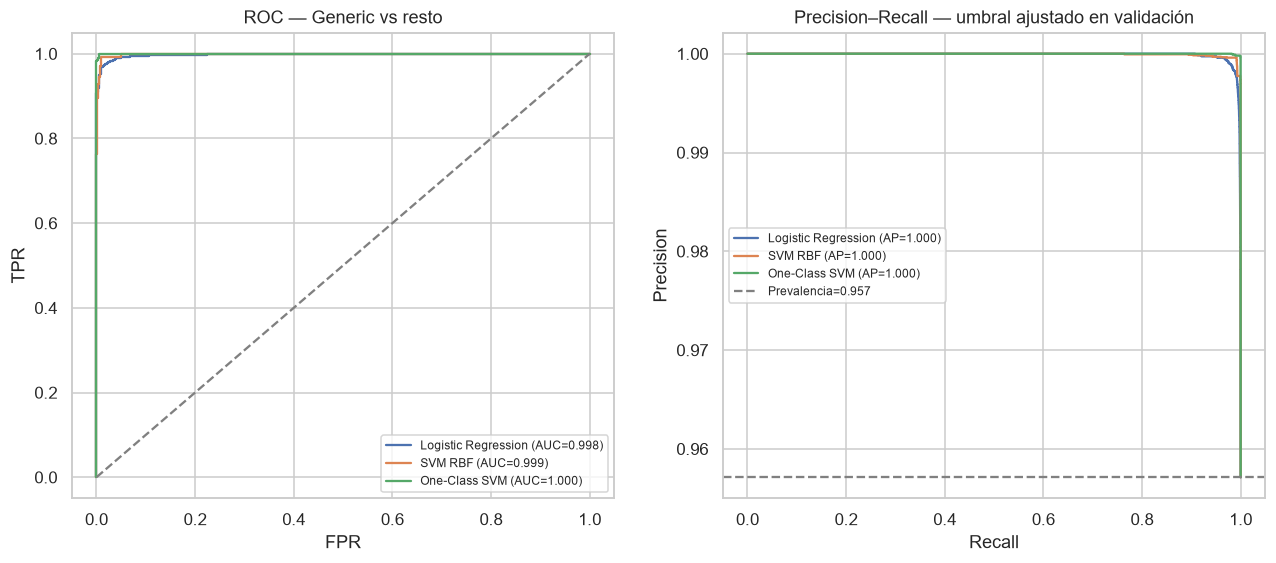

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, d in binary_details.items():
    fpr, tpr, _ = roc_curve(y_test_anom, d["scores"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test_anom, d['scores']):.3f})")
    p, r, _ = precision_recall_curve(y_test_anom, d["scores"])
    axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(y_test_anom, d['scores']):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="ROC — Generic vs resto", xlabel="FPR", ylabel="TPR")
axes[1].axhline(y_test_anom.mean(), ls="--", color="gray", label=f"Prevalencia={y_test_anom.mean():.3f}")
axes[1].set(title="Precision–Recall — umbral ajustado en validación", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8)
plt.savefig(VIS_DIR / "10_anomalia_curvas_roc_pr.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

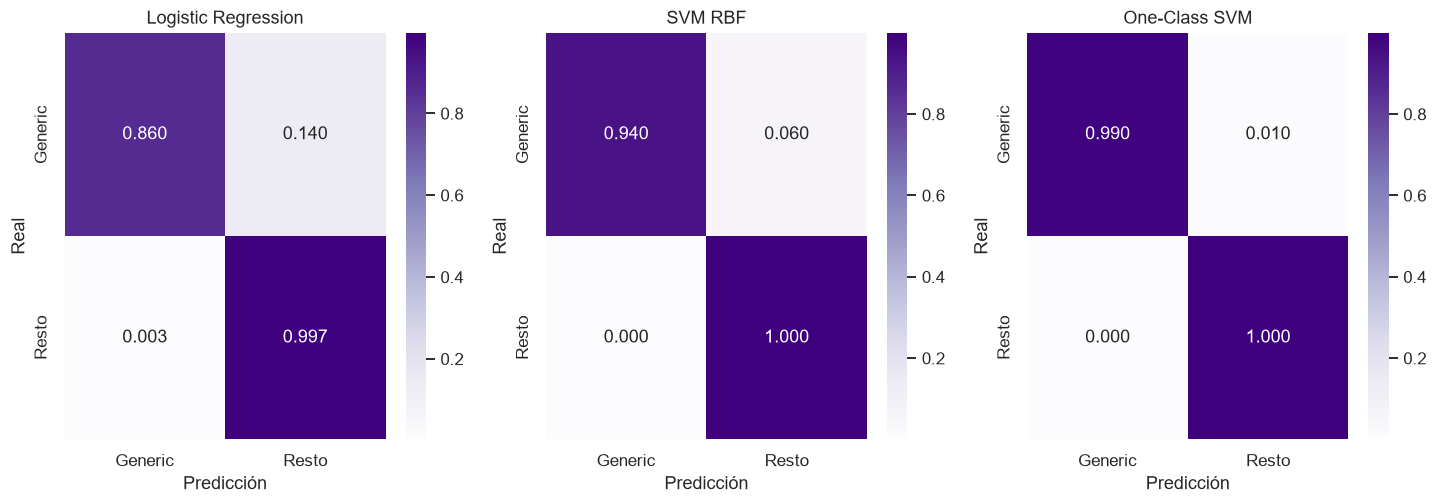

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, d) in zip(axes, binary_details.items()):
    cm = confusion_matrix(y_test_anom, d["pred"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".3f", cmap="Purples", xticklabels=["Generic", "Resto"], yticklabels=["Generic", "Resto"], ax=ax)
    ax.set(title=name, xlabel="Predicción", ylabel="Real")
plt.savefig(VIS_DIR / "11_anomalia_matrices_confusion.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

## 7. Análisis de errores e importancia

Se usan índices posicionales coherentes con `X_test.reset_index(drop=True)`, evitando mezclar `iloc`
con etiquetas originales. El recall por ataque permite ver qué clases son más difíciles.

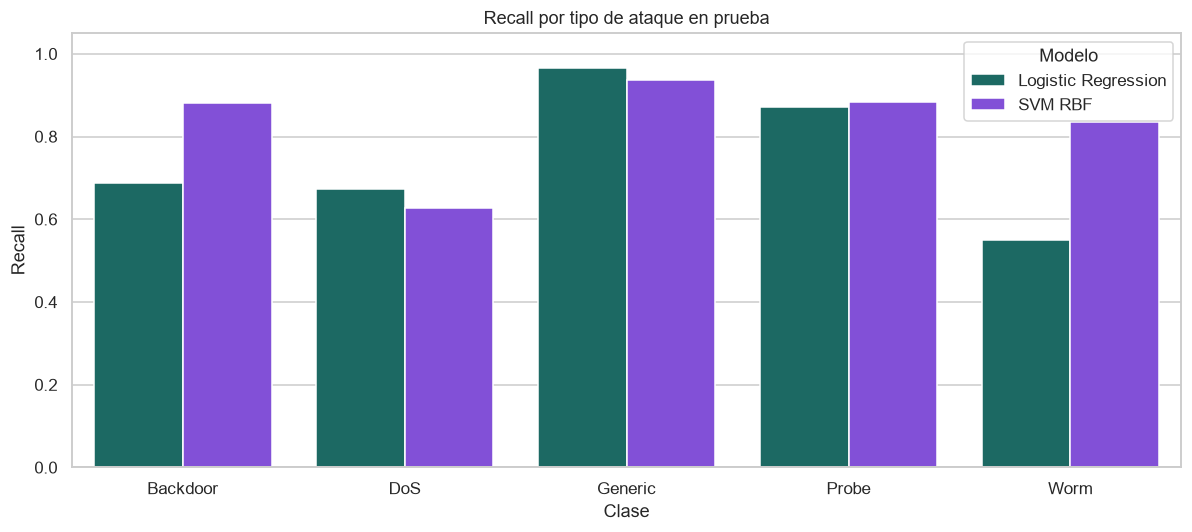

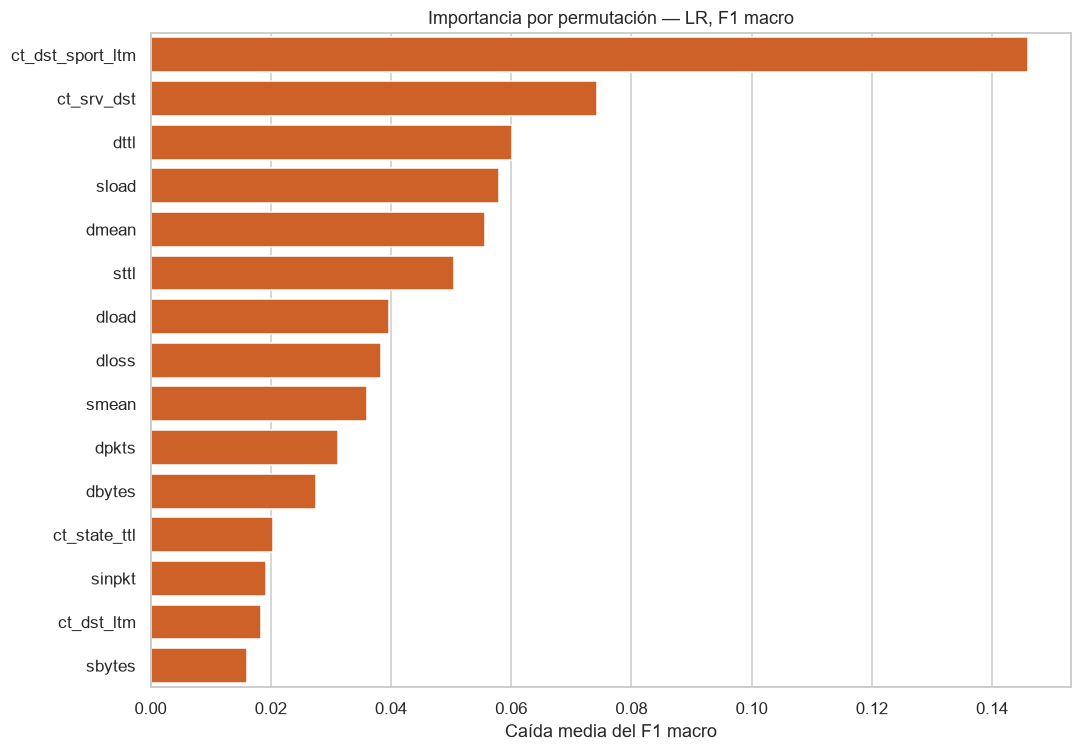

,variable,importancia,std
0,ct_dst_sport_ltm,0.145911,0.001663
1,ct_srv_dst,0.074200,0.004304
2,dttl,0.060220,0.006207
3,sload,0.057946,0.003195
4,dmean,0.055675,0.002248
5,sttl,0.050410,0.004703
6,dload,0.039612,0.002219
7,dloss,0.038413,0.001206
8,smean,0.036003,0.001410
9,dpkts,0.031240,0.002138


In [21]:
recall_rows = []
for r in model_results:
    report = classification_report(y_test, r["pred"], target_names=class_names, output_dict=True, zero_division=0)
    for cls in class_names:
        recall_rows.append({"Modelo": r["Modelo"], "Clase": cls, "Recall": report[cls]["recall"]})
recall_df = pd.DataFrame(recall_rows)
plt.figure(figsize=(11, 5))
sns.barplot(data=recall_df, x="Clase", y="Recall", hue="Modelo", palette=["#0F766E", "#7C3AED"])
plt.ylim(0, 1.05)
plt.title("Recall por tipo de ataque en prueba")
savefig("12_analisis_errores_por_ataque.png")

# Importancia por permutación sobre una muestra de prueba; el modelo nunca se reajusta aquí.
pi_idx = stratified_sample_indices(y_test, min(3500, len(y_test)), RANDOM_STATE + 7)
perm = permutation_importance(
    best_lr, X_test_sup.iloc[pi_idx], y_test[pi_idx], scoring="f1_macro",
    n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({"variable": selected_features, "importancia": perm.importances_mean, "std": perm.importances_std}).sort_values("importancia", ascending=False)
importance_df.to_csv(RES_DIR / "importancia_permutacion_lr.csv", index=False)
plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df.head(15), x="importancia", y="variable", color="#EA580C")
plt.title("Importancia por permutación — LR, F1 macro")
plt.xlabel("Caída media del F1 macro")
plt.ylabel("")
savefig("13_importancia_permutacion.png")
display(importance_df.head(15).reset_index(drop=True))

## 8. Conclusiones y limitaciones

- La evaluación principal corresponde a **cinco ataques**, no a normal/malicioso. `Generic` se mantiene
  como ataque en todo el análisis.
- El modelo recomendado dentro de este CSV es el de mayor F1 macro en la prueba retenida; accuracy no
  es suficiente porque la deduplicación produce fuerte desbalance.
- La selección por Mutual Information se ajusta exclusivamente con entrenamiento y las variables
  seleccionadas sí alimentan LR y SVM. Escalamiento e hiperparámetros se aprenden dentro de pipelines
  sobre muestras de entrenamiento; validación solo se usa para diagnóstico y umbral binario.
- One-Class SVM es aquí un experimento de novedad respecto a `Generic`; un desempeño alto no demuestra
  detección de tráfico benigno porque no existe clase Normal.
- Para producción se requiere incorporar tráfico normal real, validación temporal, calibración y costos
  de falsos positivos/falsos negativos. El muestreo acelera SVM, pero puede omitir subpatrones raros.

In [22]:
# Resumen reproducible para README, guion y presentación.
best_supervised_name = metrics_multiclass["F1 macro"].idxmax()
summary_supervised = {
    "dataset": {
        "filas_originales": int(len(df_raw)), "columnas": int(df_raw.shape[1]),
        "features": int(len(FEATURES)), "faltantes": missing_total,
        "duplicados_exactos": exact_duplicates, "filas_unicas": int(len(df)),
        "clases_originales": {k: int(v) for k, v in class_counts_raw.items()},
        "clases_unicas": {k: int(v) for k, v in class_counts_unique.items()},
        "sin_proto_service_state": True, "sin_clase_normal": True,
    },
    "splits": {"train": len(X_train), "validacion": len(X_val), "prueba": len(X_test),
               "lr_grid_train": len(X_train_lr), "svm_grid_train": len(X_train_svm)},
    "variables_seleccionadas": selected_features,
    "supervisado_multiclase": metrics_multiclass.reset_index().to_dict(orient="records"),
    "mejor_supervisado": best_supervised_name,
    "generic_vs_resto": metrics_binary.reset_index().to_dict(orient="records"),
    "one_class_best": {k: (float(v) if isinstance(v, (float, np.floating)) else v)
                       for k, v in best_oc.items() if k != "model"},
    "top_mi_features": mi_df.head(10)["variable"].tolist(),
    "top_permutation_features": importance_df.head(10)["variable"].tolist(),
    "runtime_minutes": float((time.time() - t0) / 60),
}
with open(RES_DIR / "resumen_supervisado.json", "w", encoding="utf-8") as f:
    json.dump(summary_supervised, f, ensure_ascii=False, indent=2)
print("Mejor modelo por F1 macro:", best_supervised_name)
print(f"Tiempo supervisado: {summary_supervised['runtime_minutes']:.1f} min")
print(f"Visualizaciones: {len(list(VIS_DIR.glob('*.png')))}")
print("Prueba retenida: no se usó para seleccionar variables, hiperparámetros ni umbrales.")

Mejor modelo por F1 macro: SVM RBF
Tiempo supervisado: 4.7 min
Visualizaciones: 14
Prueba retenida: no se usó para seleccionar variables, hiperparámetros ni umbrales.
